# 16. 超解像・顔復元の手法比較：Real-ESRGAN / StableSR / DiffBIR / SUPIR / GFPGAN / CodeFormer / DifFace（有料枠向け）

**セミナー対応章**：第3章（1）超解像（スライドの「手法の比較」2 枚：風景の超解像と顔画像の超解像）　｜　**推奨ランタイム**：**A100 ＋ ハイメモリ（有料）**　｜　**所要時間**：初回 約30〜40分（ライブラリのインストールとモデル 約23GB のダウンロードを含む）

スライドの 2 つの比較実験を、**ネットから取得できる画像** で再現します。
講師がスライドの図を作ったときと同じ **ComfyUI のワークフロー**（配布の `comfyui_workflows/api/` にある JSON）を、Colab 上の ComfyUI に送って実行します。

| 比較 | 画像 | 劣化 | 手法 |
|---|---|---|---|
| 1. 風景の超解像 | Kodak 標準テスト画像（評価用フリー画像） | 縦横 1/4 縮小＋ノイズ σ=15 | Real-ESRGAN（GAN）・StableSR・DiffBIR・SUPIR（拡散） |
| 2. 顔の超解像 | FFHQ（Flickr の顔写真データセット）の 1 枚 | 縦横 1/4 縮小＋ノイズ σ=25 ／ 縦横 1/4 縮小＋ボケ | GFPGAN（GAN）・CodeFormer（Transformer）・DiffBIR・SUPIR・DifFace（拡散） |

無料枠（T4・RAM 約12GB）では SUPIR が **RAM 不足で停止** するため、有料枠で実行してください。

> **ローカルPC で ComfyUI を起動済みの場合**：下の `COMFY_URL` に `"http://127.0.0.1:8188"` を設定すると、インストールを飛ばして手元の ComfyUI で実行できます
> （必要なカスタムノードとモデルは `comfyui_workflows/README.md` の一覧を見て、手元の ComfyUI に入れておいてください）。

### ⚠ 有料枠を使う前に（重要）
- ［ランタイム］→［ランタイムのタイプを変更］で **A100 GPU** を選び、**「ハイメモリ」をオン**
- 接続後、右上の［リソース］で **コンピューティングユニット（CU）の消費レートと残高** を確認（詳しくは GitHub の docs/Colab有料枠ガイド.pdf）
- 使い終わったら **［ランタイム］→［ランタイムを接続解除して削除］**（接続している間は CU が減り続けます）
- **ライセンス**：SUPIR（独自）・StableSR・CodeFormer・DifFace（S-Lab License）は **非商用** です。FFHQ の画像は個々の写真のライセンス（CC BY など）に従います

In [1]:
# ===== 共通セットアップ（このセルを最初に1回だけ実行してください） =====
import os, sys, subprocess, time, urllib.request

IN_COLAB = "google.colab" in sys.modules

def pip_install(*pkgs):
    """足りないライブラリを静かにインストールする（Colab用）"""
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=True)

if IN_COLAB:
    # Colabには torch / transformers / diffusers などが最初から入っています。
    # 不足分だけ追加します（1〜2分）。
    pip_install("spandrel", "lpips", "diffusers>=0.30", "accelerate", "peft")

import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32
print(f"実行環境: {'Google Colab' if IN_COLAB else 'ローカルPC'} / torch {torch.__version__}")
if DEVICE == "cuda":
    p = torch.cuda.get_device_properties(0)
    print(f"GPU: {p.name}  VRAM: {p.total_memory / 1024**3:.1f} GB")
else:
    print("GPUが見つかりません。Colabでは［ランタイム］→［ランタイムのタイプを変更］→ T4 GPU を選んでください。")

WEIGHTS_DIR = os.path.abspath("weights")
os.makedirs(WEIGHTS_DIR, exist_ok=True)

def download(url, name=None):
    """学習済み重みをダウンロード（2回目以降はキャッシュを使う）"""
    path = os.path.join(WEIGHTS_DIR, name or url.split("/")[-1])
    if not os.path.exists(path):
        print("downloading", url)
        urllib.request.urlretrieve(url, path + ".part")      # 途中で止めても壊れたファイルが残らないように
        os.replace(path + ".part", path)
    return path

def load_sample(name="astronaut", size=None):
    """scikit-image同梱のサンプル画像（ネット不要）。name: astronaut / coffee / chelsea / rocket"""
    from skimage import data
    img = Image.fromarray(getattr(data, name)()).convert("RGB")
    if size:
        img = img.resize((size, size) if isinstance(size, int) else size, Image.BICUBIC)
    return img

def load_portrait():
    """顔が大きく写った 512x512 の高画質画像（Kodak 標準テスト画像 kodim04 の上部を切り出し）。
    Kodak 画像は画像処理の評価用に広く使われているフリーのテスト画像（r0k.us/graphics/kodak/）。
    ダウンロードできない場合は astronaut で代用。"""
    try:
        img = Image.open(download("https://r0k.us/graphics/kodak/kodak/kodim04.png")).convert("RGB")
        return img.crop((0, 160, 512, 672))
    except Exception as e:
        print("kodim04 を取得できなかったため astronaut を使います:", e)
        return load_sample("astronaut")

def to_np(img):
    """PIL → float32 [0,1] の (H,W,3) 配列"""
    return np.asarray(img.convert("RGB"), dtype=np.float32) / 255.0

def to_pil(arr):
    return Image.fromarray((np.clip(arr, 0, 1) * 255 + 0.5).astype(np.uint8))

def to_tensor(img):
    """PIL / ndarray → (1,3,H,W) テンソル"""
    a = to_np(img) if isinstance(img, Image.Image) else img
    return torch.from_numpy(np.ascontiguousarray(a, dtype=np.float32)).permute(2, 0, 1)[None].contiguous()

def tensor_to_pil(t):
    return to_pil(t[0].detach().float().clamp(0, 1).permute(1, 2, 0).cpu().numpy())

def psnr(a, b):
    a, b = to_np(a) if isinstance(a, Image.Image) else a, to_np(b) if isinstance(b, Image.Image) else b
    return 10 * np.log10(1.0 / np.mean((a - b) ** 2))

def ssim(a, b):
    from skimage.metrics import structural_similarity
    a, b = to_np(a) if isinstance(a, Image.Image) else a, to_np(b) if isinstance(b, Image.Image) else b
    return structural_similarity(a, b, channel_axis=2, data_range=1.0)

def show(images, titles=None, size=4, rows=1):
    """画像を横に並べて表示（タイトルは文字化け防止のため英数字推奨）"""
    n = len(images)
    cols = (n + rows - 1) // rows
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows), squeeze=False)
    for i, ax in enumerate(axes.flat):
        ax.axis("off")
        if i < n:
            im = images[i]
            if isinstance(im, np.ndarray) and im.ndim == 2:
                ax.imshow(im, cmap="gray")                      # 2次元配列（マップ・スペクトル）は自動スケール
            else:
                if isinstance(im, np.ndarray) and im.dtype != np.uint8:
                    im = np.clip(im, 0, 1)                      # float 画像は 0〜1 に収める
                ax.imshow(im)
            if titles:
                ax.set_title(titles[i], fontsize=11)
    plt.tight_layout()
    plt.show()

def gpu_mem():
    if DEVICE == "cuda":
        print(f"GPUメモリ使用量(ピーク): {torch.cuda.max_memory_allocated() / 1024**3:.2f} GB")

実行環境: ローカルPC / torch 2.11.0+cu128
GPU: NVIDIA GeForce RTX 5090 Laptop GPU  VRAM: 23.9 GB


In [2]:
COMFY_URL = os.environ.get("COMFY_URL")   # ローカルの ComfyUI を使う場合は "http://127.0.0.1:8188" などを設定
COMFY_DIR = "/content/ComfyUI" if IN_COLAB else os.path.abspath("ComfyUI")
REPO_DIR = os.path.abspath("genai-image-restoration-seminar")   # 本講座の GitHub リポジトリ（ワークフローとカスタムノード）

try:
    import psutil
    ram = psutil.virtual_memory().total / 1024**3
    print(f"システムRAM: {ram:.0f} GB")
    if COMFY_URL is None and ram < 30:
        print("⚠ RAM が不足しています。［ランタイムのタイプを変更］で「ハイメモリ」をオンにしてください。")
except ImportError:
    pass

システムRAM: 63 GB


## 1. ComfyUI とカスタムノードのインストール（Colab・初回のみ 約5〜10分）
講師の PC で動作を確認した版（コミット）に固定して取得します。最新版ではノードの仕様が変わって動かないことがあるためです。

In [3]:
import json, shutil, glob

def sh(cmd, cwd=None):
    print("$", cmd)
    subprocess.run(cmd, shell=True, check=True, cwd=cwd)

def git_get(url, dst, commit):
    """GitHub のリポジトリを、指定したコミットの状態で取得する"""
    if os.path.exists(os.path.join(dst, ".git")):
        return
    os.makedirs(dst, exist_ok=True)
    sh("git init -q", cwd=dst)
    sh(f"git fetch -q --depth 1 {url} {commit}", cwd=dst)
    sh("git checkout -q FETCH_HEAD", cwd=dst)

NODES = [   # (URL, フォルダ名, コミット)
    ("https://github.com/kijai/ComfyUI-SUPIR", "ComfyUI-SUPIR", "99d49e912c905ce1aaf7d15898f550b40fb3e6cc"),
    ("https://github.com/jtscmw01/ComfyUI-DiffBIR", "ComfyUI-DiffBIR", "5f738b657d8004ac9581e13f29c34be6990b58ec"),
    ("https://github.com/gameltb/Comfyui-StableSR", "Comfyui-StableSR", "fb6010436f6eb21037ab12dbcbf078a9d4021187"),
    ("https://github.com/comfyorg/comfyui_gfpgan", "comfyui_gfpgan", "77577e49ae49e59e44098549d8d04ab2cba87fda"),
    ("https://github.com/mav-rik/facerestore_cf", "facerestore_cf", "ff4d7a5c102441d8f058dd6135797ffb57b6c6ad"),
]

if COMFY_URL is None:
    git_get("https://github.com/comfyanonymous/ComfyUI", COMFY_DIR, "64b8457f55cd7fb54ca7a956d9c73b505e903e0c")
    sh(f"{sys.executable} -m pip install -q -r requirements.txt", cwd=COMFY_DIR)
    nodes_dir = os.path.join(COMFY_DIR, "custom_nodes")
    for url, name, commit in NODES:
        git_get(url, os.path.join(nodes_dir, name), commit)
    # カスタムノードが使うライブラリ（gfpgan は古い basicsr を引き込まないよう --no-deps で入れる）
    pip_install("omegaconf", "einops", "timm", "ftfy", "pytorch_lightning", "open-clip-torch", "kornia",
                "basicsr-fixed", "facexlib", "lmdb", "yapf", "addict", "gdown")
    sh(f"{sys.executable} -m pip install -q --no-deps gfpgan")
    # SUPIR ノードは transformers 5 系では CLIP を読み込めない（内部構造が変わったため）。4 系の最終版に入れ替える
    pip_install("transformers==4.57.6")
    # CodeFormer ノード（facerestore_cf）は pip の basicsr に CodeFormer が登録されている前提なので、同梱のファイルをコピーする
    import importlib.util
    bs_archs = os.path.join(importlib.util.find_spec("basicsr").submodule_search_locations[0], "archs")
    for fn in ["vqgan_arch.py", "codeformer_arch.py"]:
        shutil.copy(os.path.join(nodes_dir, "facerestore_cf", "basicsr", "archs", fn), bs_archs)
    # 講座のカスタムノード（劣化画像の作成・DifFace）とワークフローは、本講座のリポジトリから取得
    if not os.path.exists(REPO_DIR):
        sh(f"git clone -q --depth 1 https://github.com/takeshi-nagata-mgu/genai-image-restoration-seminar {REPO_DIR}")
    shutil.copytree(os.path.join(REPO_DIR, "comfyui_workflows", "custom_nodes", "seminar_nodes"),
                    os.path.join(nodes_dir, "seminar_nodes"), dirs_exist_ok=True)
    # DifFace 本体（DifFace ノードが別プロセスで呼び出す）
    git_get("https://github.com/zsyOAOA/DifFace", os.path.join(COMFY_DIR, "DifFace"), "5c9ab801b2872544b221d4bfdeead7d430af4ed2")
    print("インストール完了")
elif not os.path.exists(REPO_DIR):
    sh(f"git clone -q --depth 1 https://github.com/takeshi-nagata-mgu/genai-image-restoration-seminar {REPO_DIR}")

$ D:\seminar_env\venv_nb16\Scripts\python.exe -m pip install -q -r requirements.txt


$ D:\seminar_env\venv_nb16\Scripts\python.exe -m pip install -q --no-deps gfpgan


インストール完了


## 2. モデルのダウンロード（Colab・初回のみ 約5〜15分、合計 約23GB）

| モデル | 用途 | 大きさ |
|---|---|---|
| `sd_xl_base_1.0` ＋ `SUPIR-v0Q` | SUPIR（SDXL を土台にした復元） | 6.9GB ＋ 2.7GB |
| `v2-1_768-ema-pruned` ＋ `webui_768v_139` | StableSR（SD2.1 を土台にした超解像） | 5.2GB ＋ 0.4GB |
| `v2-1_512-ema-pruned` ＋ `v2.pth` ＋ 劣化除去用の小さな CNN | DiffBIR | 5.2GB ＋ 1.5GB ＋ 0.2GB |
| `RealESRGAN_x4plus` / `GFPGANv1.4` / `codeformer` | GAN・Transformer 系 | 各 0.1〜0.4GB |

Stable Diffusion 2.1 は Stability AI の公式配布が終了したため、同じファイル（ハッシュ値が一致）を配布している `sd2-community` から取得します。
DifFace の重み（約 0.6GB）と顔検出の重みは、初回の実行時に自動でダウンロードされます。

In [4]:
from huggingface_hub import hf_hub_download

def get_url(url, folder):
    """GitHub などの URL から直接ダウンロード（途中で止めても壊れたファイルが残らないように）"""
    os.makedirs(folder, exist_ok=True)
    path = os.path.join(folder, url.split("/")[-1])
    if not os.path.exists(path):
        urllib.request.urlretrieve(url, path + ".part")
        os.replace(path + ".part", path)

if COMFY_URL is None:
    M = os.path.join(COMFY_DIR, "models")
    HF_FILES = [   # (リポジトリ, ファイル名, 置き場所)
        ("stabilityai/stable-diffusion-xl-base-1.0", "sd_xl_base_1.0.safetensors", "checkpoints"),
        ("Kijai/SUPIR_pruned", "SUPIR-v0Q_fp16.safetensors", "checkpoints"),
        ("sd2-community/stable-diffusion-2-1", "v2-1_768-ema-pruned.safetensors", "checkpoints"),
        ("Iceclear/StableSR", "webui_768v_139.ckpt", "stablesr"),
        ("sd2-community/stable-diffusion-2-1-base", "v2-1_512-ema-pruned.ckpt", "diffbir"),
        ("lxq007/DiffBIR-v2", "v2.pth", "diffbir"),
        ("lxq007/DiffBIR", "face_swinir_v1.ckpt", "diffbir"),
    ]
    for repo, fn, sub in HF_FILES:
        if not os.path.exists(os.path.join(M, sub, fn)):
            t = time.time()
            hf_hub_download(repo, fn, local_dir=os.path.join(M, sub))
            print(f"{fn}: {time.time()-t:.0f}s")
    get_url("https://github.com/cszn/KAIR/releases/download/v1.0/BSRNet.pth", os.path.join(M, "diffbir"))
    get_url("https://github.com/xinntao/Real-ESRGAN/releases/download/v0.1.0/RealESRGAN_x4plus.pth", os.path.join(M, "upscale_models"))
    get_url("https://github.com/TencentARC/GFPGAN/releases/download/v1.3.0/GFPGANv1.4.pth", os.path.join(M, "face_restoration"))
    get_url("https://github.com/sczhou/CodeFormer/releases/download/v0.1.0/codeformer.pth", os.path.join(M, "facerestore_models"))
    print("ダウンロード完了")

ダウンロード完了


D:\seminar_env\venv_nb16\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 3. ComfyUI サーバーを裏で起動（1〜2分）

In [5]:
import urllib.parse

if COMFY_URL is None:
    log = open(os.path.join(COMFY_DIR, "comfyui.log"), "w")
    # DiffBIR ノードは「ComfyUI-DiffBIR.model」という名前で自分を import するので、custom_nodes フォルダを検索パスに加える
    env = dict(os.environ, PYTHONPATH=os.pathsep.join([os.path.join(COMFY_DIR, "custom_nodes"), os.environ.get("PYTHONPATH", "")]))
    server = subprocess.Popen([sys.executable, "main.py", "--listen", "127.0.0.1", "--port", "8188"],
                              cwd=COMFY_DIR, stdout=log, stderr=subprocess.STDOUT, env=env)
    COMFY_URL = "http://127.0.0.1:8188"
    for _ in range(300):
        try:
            urllib.request.urlopen(COMFY_URL + "/system_stats", timeout=2); break
        except Exception:
            if server.poll() is not None:
                raise RuntimeError("ComfyUI が起動できませんでした。comfyui.log を確認してください")
            time.sleep(2)
print("ComfyUI:", json.load(urllib.request.urlopen(COMFY_URL + "/system_stats"))["system"]["comfyui_version"])

# 必要なノードが読み込めたか確認（足りないと、ワークフローの実行時にエラーになる）
info = json.load(urllib.request.urlopen(COMFY_URL + "/object_info"))
need = ["SUPIR_sample", "DiffBIR_sample", "ApplyStableSRUpscaler", "GFPGANRestorer", "FaceRestoreCFWithModel",
        "SRDegradationNode", "CleanGaussianBlurNode", "DifFaceRestoreNode"]
missing = [n for n in need if n not in info]
print("ノード：すべて読み込み済み" if not missing else f"⚠ 読み込めなかったノード: {missing}（comfyui.log の IMPORT FAILED を確認）")

ComfyUI: 0.20.1


ノード：すべて読み込み済み


## 4. API でワークフローを実行する関数（ノートブック 15 と同じ）

In [6]:
import io, uuid

def upload_image(pil_img, name):
    """画像を ComfyUI の input フォルダに送る（/upload/image API）"""
    buf = io.BytesIO(); pil_img.save(buf, format="PNG")
    boundary = uuid.uuid4().hex
    body = (f"--{boundary}\r\nContent-Disposition: form-data; name=\"image\"; filename=\"{name}\"\r\n"
            f"Content-Type: image/png\r\n\r\n").encode() + buf.getvalue() + \
           f"\r\n--{boundary}\r\nContent-Disposition: form-data; name=\"overwrite\"\r\n\r\ntrue\r\n--{boundary}--\r\n".encode()
    req = urllib.request.Request(COMFY_URL + "/upload/image", data=body,
                                 headers={"Content-Type": f"multipart/form-data; boundary={boundary}"})
    return json.load(urllib.request.urlopen(req))["name"]

def run_workflow(workflow, timeout=3600):
    """ワークフローを実行し、保存された画像を {ノードID: [PIL画像, ...]} で返す"""
    # ComfyUI は入力が変わらないノードを再実行しない（キャッシュ）。保存ノードだけは毎回実行させて、結果を必ず受け取る
    workflow = json.loads(json.dumps(workflow))
    tag = uuid.uuid4().hex[:6]
    for node in workflow.values():
        if node["class_type"] == "SaveImage":
            node["inputs"]["filename_prefix"] = node["inputs"]["filename_prefix"].strip() + "_" + tag
    req = urllib.request.Request(COMFY_URL + "/prompt", data=json.dumps({"prompt": workflow}).encode(),
                                 headers={"Content-Type": "application/json"})
    pid = json.load(urllib.request.urlopen(req))["prompt_id"]
    t = time.time()
    while time.time() - t < timeout:
        hist = json.load(urllib.request.urlopen(f"{COMFY_URL}/history/{pid}"))
        if pid in hist:
            st = hist[pid].get("status", {})
            if st.get("status_str") == "error":
                raise RuntimeError(json.dumps(st.get("messages"), ensure_ascii=False)[:2000])
            outs = {}
            for nid, o in hist[pid]["outputs"].items():
                for im in o.get("images", []):
                    q = urllib.parse.urlencode({"filename": im["filename"], "subfolder": im["subfolder"], "type": im["type"]})
                    outs.setdefault(nid, []).append(Image.open(io.BytesIO(urllib.request.urlopen(f"{COMFY_URL}/view?{q}").read())).convert("RGB"))
            print(f"完了: {time.time()-t:.0f}s")
            return outs
        time.sleep(2)
    raise TimeoutError("ComfyUI の処理がタイムアウトしました")

def load_workflow(name):
    with open(os.path.join(REPO_DIR, "comfyui_workflows", "api", name), encoding="utf-8") as f:
        return json.load(f)

結果を並べて表示する関数です。各手法の下に、正解との **PSNR**（画素の一致度、高いほど良い）と **LPIPS**（見た目の違い、低いほど良い）を表示します。

In [7]:
import lpips
lp = lpips.LPIPS(net="alex", verbose=False)

def lpips_dist(a, b):
    t = lambda im: torch.from_numpy(np.asarray(im, np.float32) / 127.5 - 1).permute(2, 0, 1)[None]
    with torch.no_grad():
        return lp(t(a), t(b)).item()

def compare(panels, gt, size=3.2, save=None):
    """panels: [(名前, PIL画像), ...]。正解と大きさをそろえて横に並べる"""
    fig, axes = plt.subplots(1, len(panels) + 1, figsize=(size * (len(panels) + 1), size * gt.height / gt.width + 0.8))
    for ax, (n, im) in zip(axes, panels + [("Ground truth", gt)]):
        im = im.resize(gt.size, Image.LANCZOS) if im.size != gt.size else im
        ax.imshow(im); ax.axis("off")
        ax.set_title(n if n == "Ground truth" else f"{n}\nPSNR {psnr(im, gt):.2f} / LPIPS {lpips_dist(im, gt):.3f}", fontsize=10)
    plt.tight_layout()
    if save:
        plt.savefig(save, dpi=100, bbox_inches="tight")
    plt.show()

os.makedirs("results", exist_ok=True)

D:\seminar_env\venv_nb16\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
D:\seminar_env\venv_nb16\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


## 5. 比較 1：風景の超解像（Real-ESRGAN / StableSR / DiffBIR / SUPIR）

配布の `sr_comparison_workflow_api.json`（スライドの図の作成に使ったもの）をそのまま使い、入力画像と縮小率だけを変えます。
- 正解：Kodak の画像（768×512）。スライドでは大きな写真を最初に 1/2 にしていましたが、ここでは縮小しません
- 劣化：**縦横 1/4（192×128）に縮小＋ノイズ σ=15** → 各手法で 4 倍に拡大

1 枚あたり A100 で約 2〜3 分です（手法ごとにモデルを読み込み直すため）。

完了: 55s


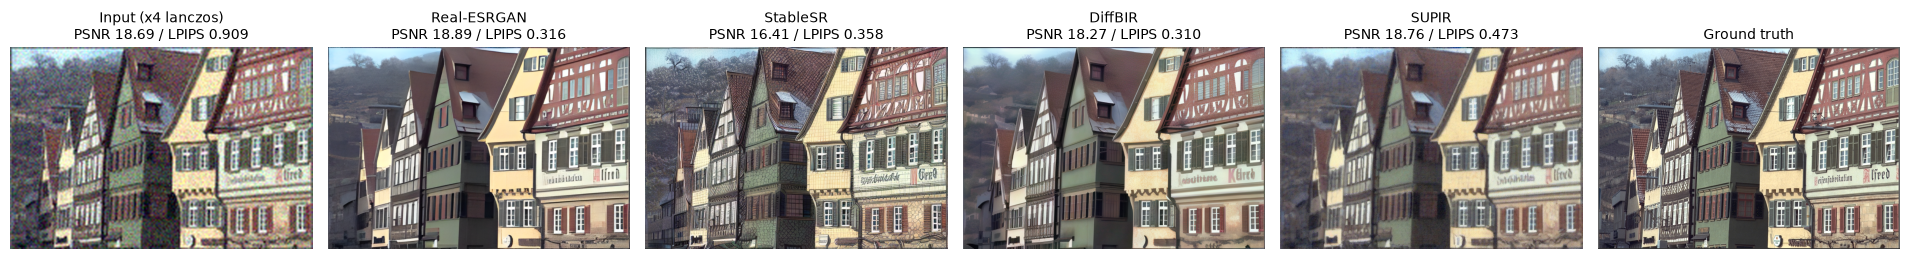

完了: 32s


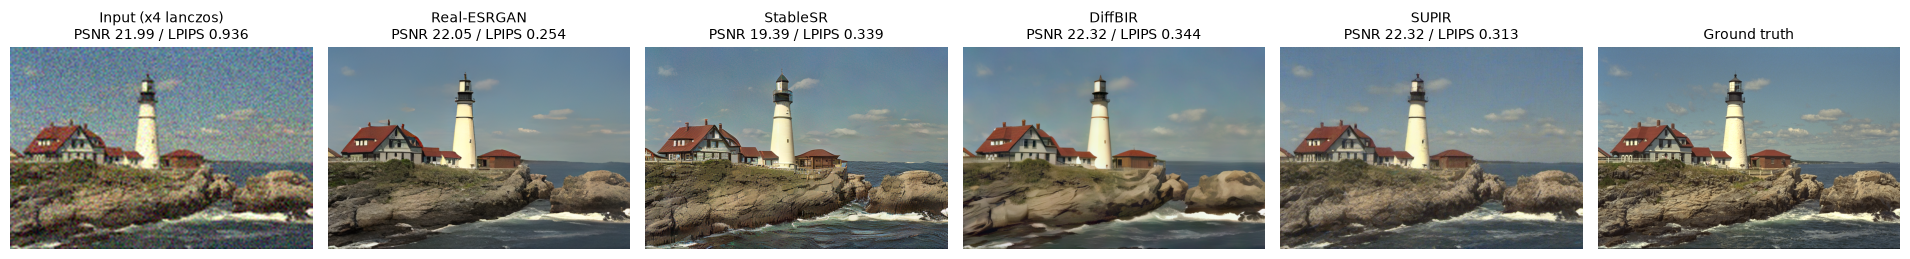

In [8]:
def kodak(n):
    return Image.open(download(f"https://r0k.us/graphics/kodak/kodak/kodim{n:02d}.png")).convert("RGB")

SR_IMAGES = [8, 21]    # kodim08（建物の壁・窓）, kodim21（灯台と岩）。ほかの番号（1〜24）でも試せます
sr_results = {}
for n in SR_IMAGES:
    wf = load_workflow("sr_comparison_workflow_api.json")
    wf["1"]["inputs"]["image"] = upload_image(kodak(n), f"kodim{n:02d}.png")
    wf["53"]["inputs"]["scale_factor"] = 1.0      # 正解は縮小しない
    outs = run_workflow(wf)
    sr_results[n] = outs
    gt = outs["54"][0]
    panels = [("Input (x4 lanczos)", outs["64"][0]), ("Real-ESRGAN", outs["13"][0]), ("StableSR", outs["28"][0]),
              ("DiffBIR", outs["32"][0]), ("SUPIR", outs["47"][0])]
    compare(panels, gt, save=f"results/sr_compare_kodim{n:02d}.png")

**観察ポイント**（スライドの説明と比べてみてください。講師の PC での結果）
- **Real-ESRGAN**：ノイズはきれいに消えるが、木組みの壁や岩の細かい模様が「塗り絵」のように平らになる
- **StableSR**：細部を最もよく描き足すが、元の画像に無い模様・形まで作る（ハルシネーション）。そのぶん PSNR は 4 手法で最も低い
- **DiffBIR**：劣化除去 → 拡散の 2 段階。全体に滑らかで、細部は控えめ
- **SUPIR**：見た目は写真らしいが、入力のノイズの一部を「質感」として残すことがある（kodim08 の壁）
- PSNR と LPIPS で順位が入れ替わることにも注目してください（第4章：知覚–歪みトレードオフ）

## 6. 比較 2：顔の超解像（GFPGAN / CodeFormer / DiffBIR / SUPIR / DifFace）

配布の `face_sr_comparison_workflow_api.json` を使います。
- 正解：FFHQ の 1 枚（1024×1024、顔の位置がそろえてある）を 512×512 に縮小したもの
- 劣化 A（スライドの上段）：**縦横 1/4（128×128）に縮小＋ノイズ σ=25**
- 劣化 B（スライドの下段）：**縦横 1/4 に縮小＋ガウスぼかし**（ノイズなし）

**注意**：FFHQ は GFPGAN・CodeFormer・DifFace などの **学習データそのもの** です。学習に使った写真なので、初めて見る写真より結果が良く見えやすい点に注意してください。
自分の顔写真で試す場合は、顔が中央に大きく写った正方形の画像（`Image.open("my.jpg")`）に差し替えてください（DiffBIR・DifFace は顔の位置がそろっている前提です）。

劣化 1 種類あたり A100 で約 2〜3 分です。

完了: 62s
劣化 A_noise


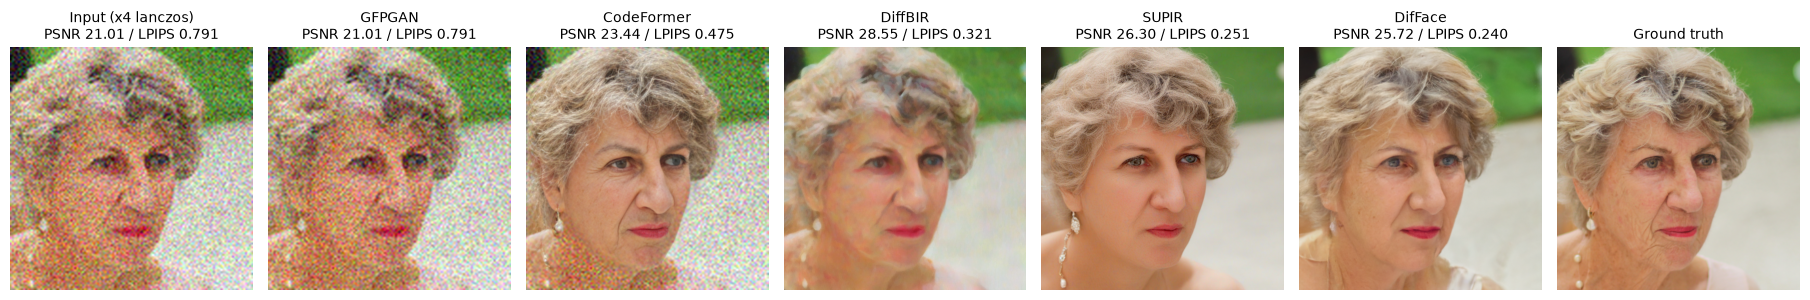

完了: 42s
劣化 B_blur


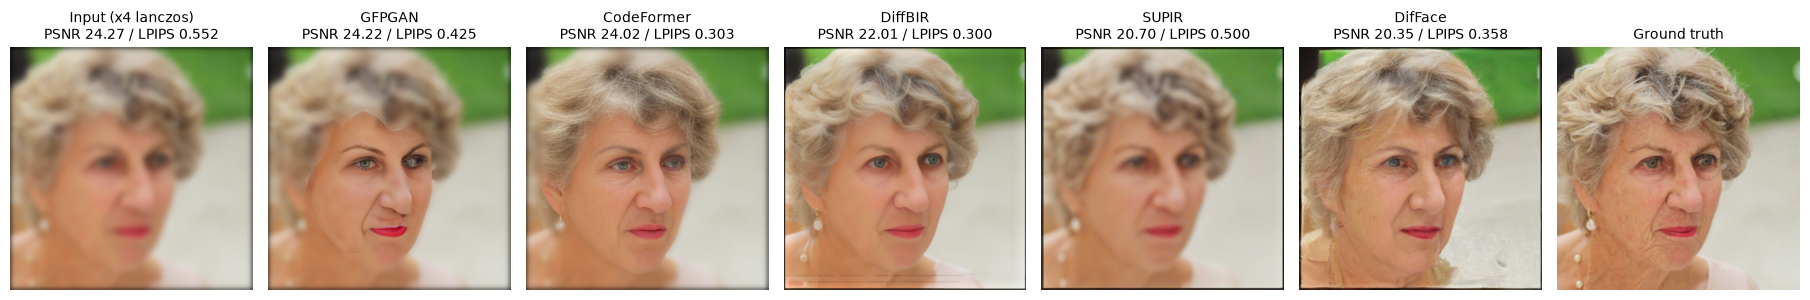

In [9]:
face = Image.open(download("https://huggingface.co/datasets/marcosv/ffhq-dataset/resolve/main/Part7/60005.png", "ffhq_60005.png")).convert("RGB")

DEGRADATIONS = {
    "A_noise": dict(noise_sigma=25, blur_k=5, blur_sigma=0.1),     # ノイズ σ=25（ぼかしは実質なし）
    "B_blur":  dict(noise_sigma=0,  blur_k=9, blur_sigma=1.6),     # ガウスぼかし（縮小後の 128px 上で σ=1.6）
}
face_name = upload_image(face, "ffhq_60005.png")
face_results = {}
for key, d in DEGRADATIONS.items():
    wf = load_workflow("face_sr_comparison_workflow_api.json")
    wf["1"]["inputs"]["image"] = face_name
    wf["2"]["inputs"]["noise_sigma"] = d["noise_sigma"]
    wf["77"]["inputs"]["kernel_size"] = d["blur_k"]
    wf["77"]["inputs"]["sigma"] = d["blur_sigma"]
    wf["88"]["inputs"]["difface_dir"] = os.path.join(COMFY_DIR, "DifFace") if os.path.exists(os.path.join(COMFY_DIR, "DifFace")) else "DifFace"
    outs = run_workflow(wf)
    face_results[key] = outs
    gt = outs["54"][0]
    panels = [("Input (x4 lanczos)", outs["64"][0]), ("GFPGAN", outs["72"][0]), ("CodeFormer", outs["75"][0]),
              ("DiffBIR", outs["32"][0]), ("SUPIR", outs["47"][0]), ("DifFace", outs["89"][0])]
    print(f"劣化 {key}")
    compare(panels, gt, size=2.6, save=f"results/face_compare_{key}.png")

**観察ポイント**（講師の PC での結果）
- **GFPGAN**：一瞬で終わるが、強いノイズ（劣化 A）はほぼそのまま残る。ボケ（劣化 B）では鼻・口の形が崩れることがある
- **CodeFormer**：顔パーツの「辞書」から選ぶので、安定して整った顔になる（顔以外の首などにはノイズが残る）。`codeformer_fidelity`（0〜1、ノード 74）で忠実さを調整できる
- **DiffBIR**：劣化 B ではくっきりするが、劣化 A では肌がまだらになった
- **SUPIR**：ノイズには強く、きれいな肌になる。一方、この設定ではボケ（劣化 B）をほとんど除去できない
- **DifFace**：LPIPS が最も良い（正解に見た目が近い）。ただし劣化 B では画像の端に乱れが出た
- **共通のリスク**：正解と見比べると、**どの手法でも目元・頬のしわがほとんど消え、若く見える** ことが分かります。
  「顔らしさの事前知識」で補うので、しわ・ほくろ・年齢感が平均的な顔に引き寄せられるのです（スライド：個人識別・証拠には使えない）

## 7. 後片付け（有料枠では必ず）
結果の画像は `results/` フォルダに保存されています（Colab では左のファイル一覧からダウンロード）。
確認が終わったら **［ランタイム］→［ランタイムを接続解除して削除］** を実行してください。

In [10]:
print(sorted(os.listdir("results")))

['face_compare_A_noise.png', 'face_compare_B_blur.png', 'l1l2', 'sr_compare_kodim08.png', 'sr_compare_kodim21.png', 'supir_result.png']
